In [9]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [21]:
class BMIState(TypedDict):
    weight_kg:float
    height_m:float
    bmi:float
    category:str

In [18]:
def calculate_bmi(state:BMIState)->BMIState:
    weight = state['weight_kg']
    height = state['height_m']
    state['bmi']=weight/(height*height)
    return state

In [22]:
def label_bmi(state: BMIState) -> BMIState:

    bmi = state['bmi']

    if bmi < 18.5:
        state["category"] = "Underweight"
    elif 18.5 <= bmi < 25:
        state["category"] = "Normal"
    elif 25 <= bmi < 30:
        state["category"] = "Overweight"
    else:
        state["category"] = "Obese"

    return state

In [23]:

# define the graph
graph=StateGraph(BMIState)


#add nodes
graph.add_node('calculate-bmi',calculate_bmi)
graph.add_node('label_bmi',label_bmi)

# add edges to your graph

graph.add_edge(START,'calculate-bmi')
graph.add_edge('calculate-bmi','label_bmi')
graph.add_edge('label_bmi',END)

# compile the graph
workflow=graph.compile()

In [24]:
# execute the graph
intial_state = {'weight_kg':80, 'height_m':1.73}

final_state=workflow.invoke(intial_state)
print(final_state)

{'weight_kg': 80, 'height_m': 1.73, 'bmi': 26.729927495071667, 'category': 'Overweight'}


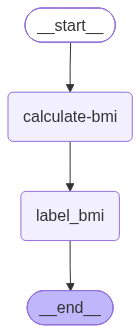

In [25]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())